# SolarGuard AI - Final model comparison (Milestone 3) FINAL
**Set Runtime > T4 GPU BEFORE running anything.** Then run top to bottom (~15-25 min on GPU).
Nothing is written to Drive. Models are chosen by VALIDATION accuracy; the test set is only used to report.

In [1]:
#Part A: Setup and data
#Step 0 - connect Google Drive (a pop-up will ask you to allow access)

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
#Step 1 - the ONLY line you have to change
# Upload the Kaggle zip to your Google Drive, then paste its path below.
# How to get the path: left sidebar > folder icon > drive > MyDrive > right-click the zip > Copy path

ZIP_PATH = "/content/drive/MyDrive/SolarguardAiproject/solar.zip"   # <-- change this

import os, random, zipfile
import numpy as np

random.seed(42); np.random.seed(42)      # same shuffling every run

assert os.path.exists(ZIP_PATH), f"Zip not found at {ZIP_PATH}. Check the path (see the steps above)."
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall("/content/solar")
print("Unzipped OK")

Unzipped OK


In [3]:
#Find your class folders:

import os
for root, dirs, files in os.walk("/content/solar"):
    print(root, "->", len(files), "files,", len(dirs), "subfolders")

/content/solar -> 0 files, 1 subfolders
/content/solar/Faulty_solar_panel -> 0 files, 6 subfolders
/content/solar/Faulty_solar_panel/Physical-Damage -> 70 files, 0 subfolders
/content/solar/Faulty_solar_panel/Clean -> 194 files, 0 subfolders
/content/solar/Faulty_solar_panel/Snow-Covered -> 124 files, 0 subfolders
/content/solar/Faulty_solar_panel/Bird-drop -> 192 files, 1 subfolders
/content/solar/Faulty_solar_panel/Bird-drop/New -> 16 files, 0 subfolders
/content/solar/Faulty_solar_panel/Dusty -> 191 files, 0 subfolders
/content/solar/Faulty_solar_panel/Electrical-damage -> 104 files, 0 subfolders


In [4]:
#Set the data path and list classes:

from pathlib import Path

IMG_EXT = ['.jpg', '.jpeg', '.png']
INCLUDE_NEW_FOLDER = False   # Bird-drop has a sub-folder "New" with 16 extra images. False = ignore it (this gives the 869 images used in our Milestone 2 numbers).

def list_images(folder):
    """Image files in one class folder (sorted, so the split is the same on every computer)."""
    files = Path(folder).rglob("*") if INCLUDE_NEW_FOLDER else Path(folder).glob("*")
    return sorted(p for p in files
                  if p.is_file() and p.suffix.lower() in IMG_EXT
                  and not p.name.startswith("._") and "__MACOSX" not in p.parts)

def find_data_dir(root):
    """Find the folder that holds one sub-folder per class (the one with the most images)."""
    best, best_n = None, 0
    for d in [Path(root)] + [p for p in Path(root).rglob("*") if p.is_dir() and "__MACOSX" not in p.parts]:
        subs = [s for s in d.iterdir() if s.is_dir() and len(list_images(s)) > 0]
        n = sum(len(list_images(s)) for s in subs)
        if len(subs) >= 2 and n > best_n:
            best, best_n = d, n
    return best

found = find_data_dir("/content/solar")
assert found is not None, "Could not find the class folders. Look at the folder listing above and set DATA_DIR by hand."
DATA_DIR = str(found)    # if this looks wrong, replace this line with: DATA_DIR = "/content/solar/<your folder name>"
print("Using data folder:", DATA_DIR)

classes = sorted([d.name for d in Path(DATA_DIR).iterdir() if d.is_dir()])
counts = {c: len(list_images(Path(DATA_DIR)/c)) for c in classes}
print(classes)
print(counts, "TOTAL:", sum(counts.values()))

Using data folder: /content/solar/Faulty_solar_panel
['Bird-drop', 'Clean', 'Dusty', 'Electrical-damage', 'Physical-Damage', 'Snow-Covered']
{'Bird-drop': 191, 'Clean': 193, 'Dusty': 190, 'Electrical-damage': 103, 'Physical-Damage': 69, 'Snow-Covered': 123} TOTAL: 869


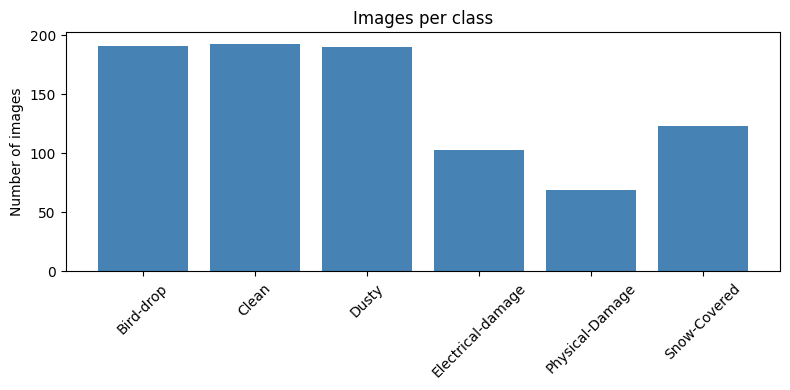

In [5]:
#Part B:Explore the data : Class distribution chart:

import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.bar(counts.keys(), counts.values(), color="steelblue")
plt.xticks(rotation=45); plt.ylabel("Number of images")
plt.title("Images per class"); plt.tight_layout(); plt.show()

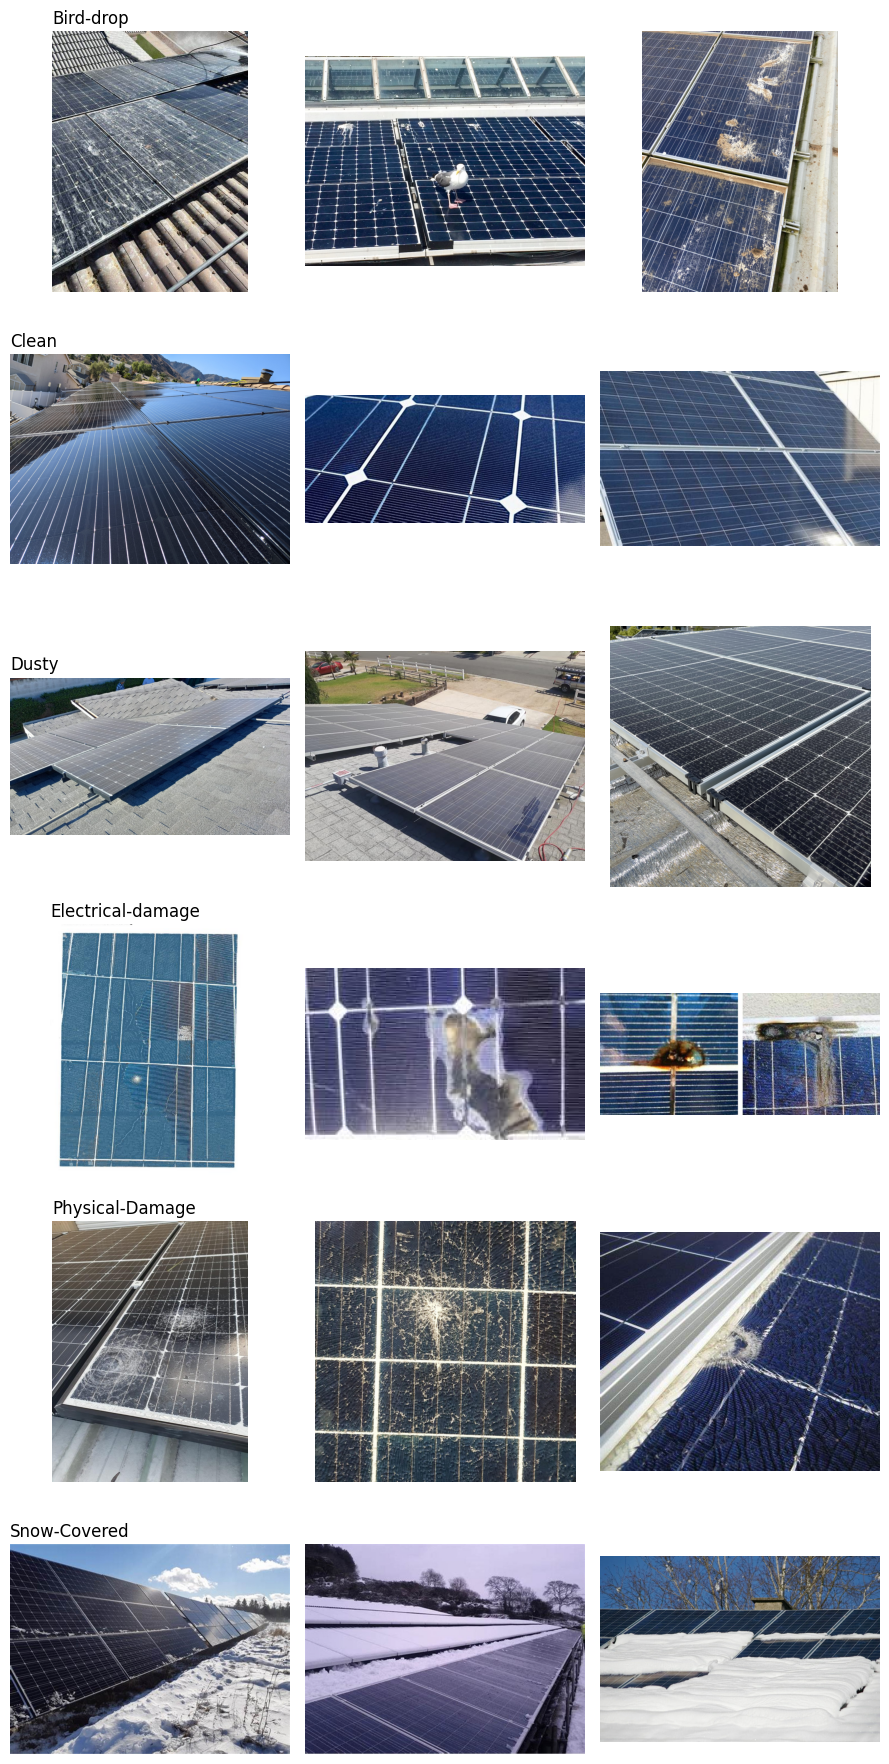

In [6]:
#Sample Images:

import cv2, random
fig, axes = plt.subplots(len(classes), 3, figsize=(9, 3*len(classes)))
for r, c in enumerate(classes):
    files = list_images(Path(DATA_DIR)/c)
    for k, p in enumerate(random.sample(files, min(3, len(files)))):
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        axes[r][k].imshow(img); axes[r][k].axis("off")
        if k == 0: axes[r][k].set_title(c, loc="left")
plt.tight_layout(); plt.show()

In [7]:
#Image Sizes:

sizes = []
for c in classes:
    for p in list_images(Path(DATA_DIR)/c)[:30]:
        img = cv2.imread(str(p))
        if img is not None: sizes.append(img.shape[:2])
print("Different sizes seen:", len(set(sizes)))
print(sizes[:10])

Different sizes seen: 128
[(250, 190), (474, 474), (2016, 1512), (2048, 1536), (2016, 1512), (720, 960), (2016, 1512), (720, 960), (720, 960), (768, 1024)]


In [8]:
#Part C: Preprocessing: Load, convert and resize all images:

IMG_SIZE = 224
X, y = [], []
for idx, c in enumerate(classes):
    for p in list_images(Path(DATA_DIR)/c):
        img = cv2.imread(str(p))
        if img is None: continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        X.append(img); y.append(idx)
X, y = np.array(X), np.array(y)
print(X.shape, y.shape)

(869, 224, 224, 3) (869,)


## 1. Split 70/20/10 and GPU check

In [9]:
import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
print("GPU:", gpus)
assert gpus, "NO GPU! Runtime > Change runtime type > T4 GPU > Save, then run everything again from the top."

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=1/3, stratify=y_temp, random_state=42)
print("Train:", len(X_train), "Val:", len(X_val), "Test:", len(X_test))
results = {}      # name -> dict(val_probs, test_probs)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Train: 608 Val: 174 Test: 87


## 2. Tuned Random Forest (classical ML baseline)

In [10]:
from skimage.feature import hog
from sklearn.ensemble import RandomForestClassifier
def extract_features(img):
    gray = cv2.resize(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), (128,128))
    h = hog(gray, orientations=9, pixels_per_cell=(16,16), cells_per_block=(2,2))
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    hist = cv2.calcHist([hsv],[0,1,2],None,[8,8,8],[0,180,0,256,0,256]).flatten()
    return np.concatenate([h, hist/(hist.sum()+1e-7)])
F_train = np.array([extract_features(i) for i in X_train])
F_val   = np.array([extract_features(i) for i in X_val])
F_test  = np.array([extract_features(i) for i in X_test])
rf = RandomForestClassifier(n_estimators=600, class_weight="balanced_subsample", random_state=42, n_jobs=-1).fit(F_train, y_train)
results["Random Forest (tuned)"] = dict(val=rf.predict_proba(F_val), test=rf.predict_proba(F_test))
print("RF val acc:", round(accuracy_score(y_val, rf.predict(F_val)),3), "| test acc:", round(accuracy_score(y_test, rf.predict(F_test)),3))

RF val acc: 0.69 | test acc: 0.724


## 3. Transfer learning with three pretrained networks
Each: frozen pretrained body + new 6-class head, augmentation, class weights, early stopping on validation loss (keeps the best epoch).

In [11]:
from tensorflow.keras import layers, Model
from sklearn.utils.class_weight import compute_class_weight
cw = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
cw = {i: float(w) for i, w in enumerate(cw)}

def build(name):
    if name == "MobileNetV2":
        base = tf.keras.applications.MobileNetV2(input_shape=(224,224,3), include_top=False, weights="imagenet")
        prep = layers.Rescaling(1/127.5, offset=-1)
    elif name == "EfficientNetB0":
        base = tf.keras.applications.EfficientNetB0(input_shape=(224,224,3), include_top=False, weights="imagenet")
        prep = None                                  # EfficientNet rescales inside itself
    elif name == "ResNet50":
        base = tf.keras.applications.ResNet50(input_shape=(224,224,3), include_top=False, weights="imagenet")
        prep = layers.Lambda(tf.keras.applications.resnet50.preprocess_input)
    base.trainable = False
    inp = layers.Input((224,224,3))
    x = layers.RandomFlip("horizontal_and_vertical")(inp)
    x = layers.RandomRotation(0.1)(x)
    x = layers.RandomZoom(0.1)(x)
    x = layers.RandomContrast(0.1)(x)
    if prep is not None: x = prep(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(len(classes), activation="softmax")(x)
    m = Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

cbs = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
       tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4)]
histories, models_ = {}, {}
for name in ["MobileNetV2", "EfficientNetB0", "ResNet50"]:
    tf.random.set_seed(42)
    m = build(name)
    h = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=40, batch_size=32, class_weight=cw, callbacks=cbs, verbose=2)
    histories[name], models_[name] = h, m
    results[name] = dict(val=m.predict(X_val, batch_size=32, verbose=0), test=m.predict(X_test, batch_size=32, verbose=0))
    print(">>>", name, "val acc:", round(accuracy_score(y_val, results[name]["val"].argmax(1)),3),
          "| test acc:", round(accuracy_score(y_test, results[name]["test"].argmax(1)),3))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/40
19/19 - 15s - 769ms/step - accuracy: 0.2303 - loss: 2.1471 - val_accuracy: 0.3563 - val_loss: 1.5893 - learning_rate: 0.0010
Epoch 2/40
19/19 - 1s - 75ms/step - accuracy: 0.4375 - loss: 1.4710 - val_accuracy: 0.5402 - val_loss: 1.2291 - learning_rate: 0.0010
Epoch 3/40
19/19 - 1s - 76ms/step - accuracy: 0.5214 - loss: 1.2198 - val_accuracy: 0.6264 - val_loss: 0.9904 - learning_rate: 0.0010
Epoch 4/40
19/19 - 2s - 80ms/step - accuracy: 0.5987 - loss: 1.0291 - val_accuracy: 0.6897 - val_loss: 0.8834 - learning_rate: 0.0010
Epoch 5/40
19/19 - 2s - 98ms/step - accuracy: 0.6398 - loss: 0.9526 - val_accuracy: 0.7069 - val_loss: 0.8406 - learning_rate: 0.0010
Epoch 6/40
19/19 - 1s - 77ms/step - accuracy: 0.6711 - loss: 0.8602 - val_accuracy: 0.7299 - val_loss: 0.7724 - learning_rate: 0.0010
Epoch 7/40
19/19 - 1s - 73ms/step - accuracy: 0.7204 - loss: 0.7488 - val_accuracy: 0.7184 - val_loss: 0.7631 - learning_rate: 0.0010
Epoch 8/40


## 4. Ensemble (average the three networks' probabilities)

In [12]:
dl = ["MobileNetV2", "EfficientNetB0", "ResNet50"]
results["Ensemble (3 CNNs)"] = dict(val=np.mean([results[n]["val"] for n in dl], axis=0), test=np.mean([results[n]["test"] for n in dl], axis=0))
results["Ensemble (3 CNNs + RF)"] = dict(val=np.mean([results[n]["val"] for n in dl+["Random Forest (tuned)"]], axis=0),
                                         test=np.mean([results[n]["test"] for n in dl+["Random Forest (tuned)"]], axis=0))

## 5. Final comparison table (choose by VALIDATION, report TEST)

In [13]:
import pandas as pd
rows = []
for n, r in results.items():
    pv, pt = r["val"].argmax(1), r["test"].argmax(1)
    rows.append([n, accuracy_score(y_val,pv), accuracy_score(y_test,pt), f1_score(y_test,pt,average="macro")])
final_df = pd.DataFrame(rows, columns=["Model","Val acc","Test acc","Test macro-F1"]).round(3).sort_values("Val acc", ascending=False)
print(final_df.to_string(index=False))
best_name = final_df.iloc[0]["Model"]
print("\nChosen by validation accuracy:", best_name)

                 Model  Val acc  Test acc  Test macro-F1
     Ensemble (3 CNNs)    0.822     0.724          0.757
Ensemble (3 CNNs + RF)    0.816     0.713          0.732
              ResNet50    0.805     0.690          0.712
           MobileNetV2    0.759     0.678          0.698
 Random Forest (tuned)    0.690     0.724          0.720
        EfficientNetB0    0.494     0.460          0.476

Chosen by validation accuracy: Ensemble (3 CNNs)


                   precision    recall  f1-score   support

        Bird-drop       0.71      0.63      0.67        19
            Clean       0.53      0.80      0.64        20
            Dusty       0.71      0.53      0.61        19
Electrical-damage       0.90      0.90      0.90        10
  Physical-Damage       1.00      0.57      0.73         7
     Snow-Covered       1.00      1.00      1.00        12

         accuracy                           0.72        87
        macro avg       0.81      0.74      0.76        87
     weighted avg       0.75      0.72      0.72        87



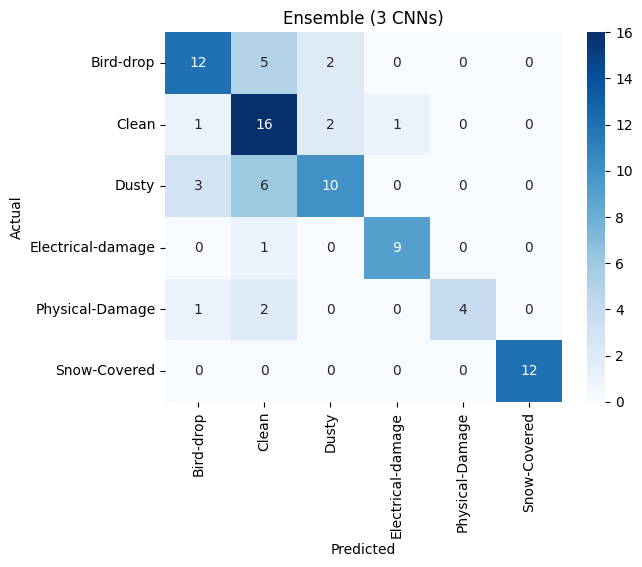

Test accuracy: 0.724 | Target 0.80 reached? False


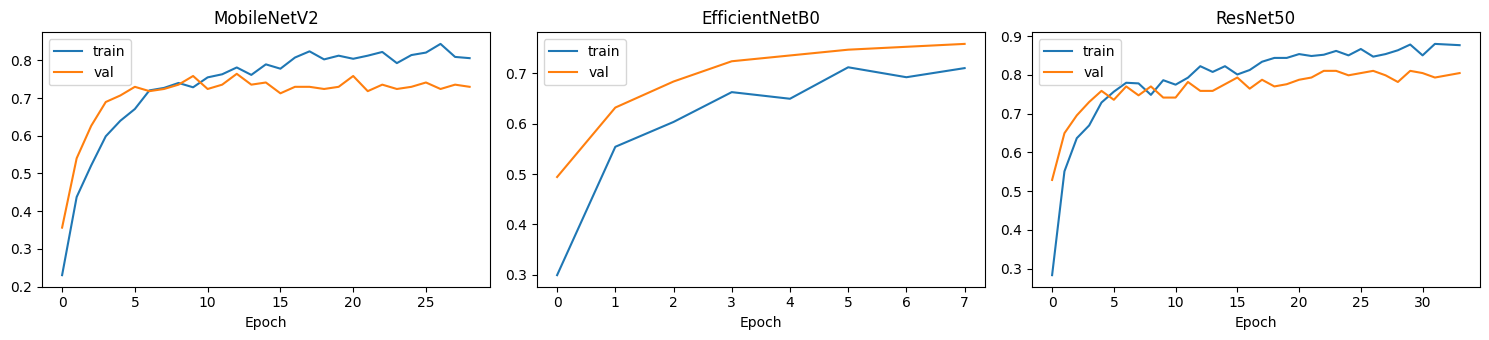

In [14]:
import matplotlib.pyplot as plt, seaborn as sns
pt = results[best_name]["test"].argmax(1)
print(classification_report(y_test, pt, target_names=classes, zero_division=0))
sns.heatmap(confusion_matrix(y_test, pt), annot=True, fmt="d", xticklabels=classes, yticklabels=classes, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(best_name); plt.show()
print("Test accuracy:", round(accuracy_score(y_test, pt),3), "| Target 0.80 reached?", accuracy_score(y_test, pt) >= 0.80)

fig, ax = plt.subplots(1, 3, figsize=(15,3.5))
for a,(n,h) in zip(ax, histories.items()):
    a.plot(h.history["accuracy"], label="train"); a.plot(h.history["val_accuracy"], label="val"); a.set_title(n); a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); plt.show()

In [15]:
import numpy as np
pair = ["MobileNetV2", "ResNet50"]
v = np.mean([results[n]["val"] for n in pair], axis=0).argmax(1)
t = np.mean([results[n]["test"] for n in pair], axis=0).argmax(1)
print("MobileNetV2 + ResNet50  val:", round(accuracy_score(y_val, v),3), "| test:", round(accuracy_score(y_test, t),3))

MobileNetV2 + ResNet50  val: 0.822 | test: 0.724


In [16]:
!pip install -q gradio

In [17]:
import gradio as gr

THRESHOLD = 0.20   # below this confidence the app says "Uncertain"
NETS = ["MobileNetV2", "EfficientNetB0", "ResNet50"]
ADVICE = {
    "Clean": "Panel is in good condition. No action needed.",
    "Dusty": "Clean the surface with water and a soft cloth or brush.",
    "Bird-drop": "Remove the droppings soon with water and a soft cloth; they can cause hot spots.",
    "Snow-Covered": "Remove the snow gently with a soft broom; do not scrape the glass.",
    "Electrical-damage": "Switch off and have a technician inspect the wiring and inverter.",
    "Physical-Damage": "Inspect for cracks; a damaged panel may need replacing by a technician.",
}

def classify(img):
    if img is None:
        return "Please upload a photo", {}, ""
    img = cv2.resize(img, (224, 224)).astype("float32")
    probs = np.mean([models_[n].predict(img[None, ...], verbose=0)[0] for n in NETS], axis=0)
    top = int(np.argmax(probs)); conf = float(probs[top])
    scores = {classes[i]: float(probs[i]) for i in range(len(classes))}
    if conf < THRESHOLD:
        return "Uncertain - please try a clearer photo", scores, ""
    return f"{classes[top]} ({conf:.0%} confident)", scores, ADVICE.get(classes[top], "")

print(classify(X_test[0]))   # quick check before launching the app

demo = gr.Interface(
    fn=classify,
    inputs=gr.Image(type="numpy", label="Upload a solar panel photo"),
    outputs=[gr.Textbox(label="Condition"),
             gr.Label(num_top_classes=6, label="Class probabilities"),
             gr.Textbox(label="Suggested action")],
    title="SolarGuard AI",
    description="Upload a photo of a solar panel and get its condition and a suggested action.")
demo.launch(share=True)

('Bird-drop (60% confident)', {'Bird-drop': 0.6037936806678772, 'Clean': 0.10114534944295883, 'Dusty': 0.19646768271923065, 'Electrical-damage': 0.014256365597248077, 'Physical-Damage': 0.03384442254900932, 'Snow-Covered': 0.05049246549606323}, 'Remove the droppings soon with water and a soft cloth; they can cause hot spots.')
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://721f693b98735c5028.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [18]:
import os
from google.colab import files
os.makedirs("/content/demo_images", exist_ok=True)
for c in range(len(classes)):
    for k, i in enumerate(np.where(y_test == c)[0][:2]):
        cv2.imwrite(f"/content/demo_images/{classes[c]}_{k+1}.jpg", cv2.cvtColor(X_test[i], cv2.COLOR_RGB2BGR))
!zip -qr /content/demo_images.zip /content/demo_images
files.download("/content/demo_images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
import os, json, re
SAVE = "/content/drive/MyDrive/SolarGuard/final"
os.makedirs(SAVE, exist_ok=True)

for n, m in models_.items():
    m.save_weights(f"{SAVE}/{n}.weights.h5")
np.savez_compressed(f"{SAVE}/data.npz", X_test=X_test, y_test=y_test, X_val=X_val, y_val=y_val)
np.savez_compressed(f"{SAVE}/probs.npz", **{re.sub(r"\W+", "_", f"{k}_{s}"): v[s] for k, v in results.items() for s in ("val", "test")})
json.dump(list(classes), open(f"{SAVE}/classes.json", "w"))
print(os.listdir(SAVE))

['MobileNetV2.weights.h5', 'EfficientNetB0.weights.h5', 'ResNet50.weights.h5', 'data.npz', 'probs.npz', 'classes.json']
